In [1]:
import os
# TensorFlow 안내 및 경고 로그 끄기 (3 = ERROR/FATAL 로그만 표시)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# oneDNN 최적화 관련 안내 문구 숨기기
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
# absl 라이브러리 초기화 전 경고(WARNING: All log messages...) 숨기기
os.environ['ABSL_LOGGING_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings(action='ignore')

from sklearn import set_config
set_config(display="text")


import FinanceDataReader as fdr
import numpy as np
import pandas as pd

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()



# Data Load

In [2]:
df = fdr.DataReader('010950')
df.columns = df.columns.str.lower()
df = df[['open', 'close']]
df.head(2)

,open,close
Date,,
2014-07-11,54400,54200
2014-07-14,54000,54200


In [3]:
df = df[-10:].copy()
df.head(2)

,open,close
Date,,
2026-09-17,143600,152800
2026-09-18,153600,149700


# 금융 Pandas

## shift(N)
    * 전일대비 가격 증감

In [5]:
df['shift'] = df['close'].shift(1)
df['close-shift'] = df['close'] - df['shift']
df

,open,close,shift,close-shift
Date,,,,
2026-09-17,143600,152800,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0
2026-09-21,149700,153900,149700.0,4200.0
2026-09-22,147400,153200,153900.0,-700.0
2026-09-23,154600,156500,153200.0,3300.0
2026-09-28,155900,164000,156500.0,7500.0
2026-09-29,163700,158200,164000.0,-5800.0
2026-09-30,159700,162000,158200.0,3800.0
2026-10-01,161800,151300,162000.0,-10700.0


## diff(N)
* N일 대비 가격 증감
* df['close'].diff(1) == df['close'] - df['close'].shift(1)

In [7]:
df['diff'] = df['close'].diff(1)
df

,open,close,shift,close-shift,diff
Date,,,,,
2026-09-17,143600,152800,NaN,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0,-3100.0
2026-09-21,149700,153900,149700.0,4200.0,4200.0
2026-09-22,147400,153200,153900.0,-700.0,-700.0
2026-09-23,154600,156500,153200.0,3300.0,3300.0
2026-09-28,155900,164000,156500.0,7500.0,7500.0
2026-09-29,163700,158200,164000.0,-5800.0,-5800.0
2026-09-30,159700,162000,158200.0,3800.0,3800.0
2026-10-01,161800,151300,162000.0,-10700.0,-10700.0


# pct_change(N)
* 전일 대비증감율
* 현재가격 - N일가격 백분위 백분율

In [8]:
df['pct'] = df['close'].pct_change(1) #1:전일 대비 / 5:주간 대비 / 20:월간대비
df

,open,close,shift,close-shift,diff,pct
Date,,,,,,
2026-09-17,143600,152800,NaN,NaN,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0,-3100.0,-0.020288
2026-09-21,149700,153900,149700.0,4200.0,4200.0,0.028056
2026-09-22,147400,153200,153900.0,-700.0,-700.0,-0.004548
2026-09-23,154600,156500,153200.0,3300.0,3300.0,0.021540
2026-09-28,155900,164000,156500.0,7500.0,7500.0,0.047923
2026-09-29,163700,158200,164000.0,-5800.0,-5800.0,-0.035366
2026-09-30,159700,162000,158200.0,3800.0,3800.0,0.024020
2026-10-01,161800,151300,162000.0,-10700.0,-10700.0,-0.066049


## rolling(N)
* N일동안의 데이터 집계
* 이동평균 : 5, 10, 20, 60, 120, 200

In [10]:
df['rolling'] = df['close'].rolling(window=5).mean()
df

,open,close,shift,close-shift,diff,pct,rolling
Date,,,,,,,
2026-09-17,143600,152800,NaN,NaN,NaN,NaN,NaN
2026-09-18,153600,149700,152800.0,-3100.0,-3100.0,-0.020288,NaN
2026-09-21,149700,153900,149700.0,4200.0,4200.0,0.028056,152133.333333
2026-09-22,147400,153200,153900.0,-700.0,-700.0,-0.004548,152266.666667
2026-09-23,154600,156500,153200.0,3300.0,3300.0,0.021540,154533.333333
2026-09-28,155900,164000,156500.0,7500.0,7500.0,0.047923,157900.000000
2026-09-29,163700,158200,164000.0,-5800.0,-5800.0,-0.035366,159566.666667
2026-09-30,159700,162000,158200.0,3800.0,3800.0,0.024020,161400.000000
2026-10-01,161800,151300,162000.0,-10700.0,-10700.0,-0.066049,157166.666667


## resample()
<pre>
D    일별 (Daily) 매일 데이터 집계
W    주별 (Weekly) 매주 일요일 기준
M    월말 (Month-end) 각 달의 마지막 날 기준
MS   월초 (Month-Start) 각 달의 첫 번째 날 기준
Q    분기말 (Quarter-end) 3, 6, 9, 12월 말 기준
YS AS   연초 (Year-Start) 매년 1월 1일 기준
YE     연말 (Year-end) 매년 12월 31일 기준
H    시간별 (Hourly) 매 시간
T    분별 (Minute) 매 분
S    초별 (Second) 매 초

In [12]:
df = fdr.DataReader('010950')
df.columns = df.columns.str.lower()
df = df[['open', 'close']]
df.head(2)

,open,close
Date,,
2014-07-11,54400,54200
2014-07-14,54000,54200


In [15]:
df = df[-100:].copy()
df

,open,close
Date,,
2026-05-08,118600,116800
2026-05-11,118700,110900
2026-05-12,112400,114300
2026-05-13,117300,115300
2026-05-14,114200,115000
...,...,...
2026-09-28,155900,164000
2026-09-29,163700,158200
2026-09-30,159700,162000


In [13]:
min(df.index), max(df.index)

(Timestamp('2014-07-11 00:00:00'), Timestamp('2026-10-02 00:00:00'))

In [14]:
df['close'].resample('ME').mean()

Date
2014-07-31     54386.666667
2014-08-31     50765.000000
2014-09-30     45234.210526
2014-10-31     40171.428571
2014-11-30     41952.500000
                  ...      
2026-06-30    107633.333333
2026-07-31    132154.545455
2026-08-31    139535.000000
2026-09-30    154115.000000
2026-10-31    158150.000000
Freq: ME, Name: close, Length: 148, dtype: float64

# 결측채우기

In [16]:
df['shift'] = df['close'].shift(5)
df.head(8)

,open,close,shift
Date,,,
2026-05-08,118600,116800,NaN
2026-05-11,118700,110900,NaN
2026-05-12,112400,114300,NaN
2026-05-13,117300,115300,NaN
2026-05-14,114200,115000,NaN
2026-05-15,114100,112100,116800.0
2026-05-18,113800,111500,110900.0
2026-05-19,111600,110100,114300.0


* bfill : 바로 아래 값으로 채우기
* ffill : 바로 위 값으로 채우기

In [17]:
#df['shift'] = df['shift']df.fillna(method='ffill')  #
df['shift'] = df['shift'].bfill()  #
df.head(10)

,open,close,shift
Date,,,
2026-05-08,118600,116800,116800.0
2026-05-11,118700,110900,116800.0
2026-05-12,112400,114300,116800.0
2026-05-13,117300,115300,116800.0
2026-05-14,114200,115000,116800.0
2026-05-15,114100,112100,116800.0
2026-05-18,113800,111500,110900.0
2026-05-19,111600,110100,114300.0
2026-05-20,110100,110800,115300.0


## 누적 수익률

### 단순 누적 수익률
* $$\text{누적 수익률} = \frac{P_t - P_0}{P_0} \times 100 (\%)$$
(현재가 - 최초가) / 최초가격 * 100


In [18]:
init_price = 10000
today_price = 15000
((today_price - init_price) / init_price) *100

50.0

### 기간별 수익률
* $$R_{\text{cumulative}} = \left[ (1 + r_1) \times (1 + r_2) \times \dots \times (1 + r_T) \right] - 1$$
* (1+R).cumprod() - 1

In [22]:
df['pct'] = df['close'].pct_change()
df['pct'] = df['pct'].bfill()
df.head(3)

,open,close,shift,pct
Date,,,,
2026-05-08,118600,116800,116800.0,-0.050514
2026-05-11,118700,110900,116800.0,-0.050514
2026-05-12,112400,114300,116800.0,0.030658


In [24]:
df['cumpro'] =  (1 + df['pct']).cumprod() - 1
df.tail(3)

,open,close,shift,pct,cumpro
Date,,,,,
2026-09-30,159700,162000,153900.0,0.024020,0.316924
2026-10-01,161800,151300,153200.0,-0.066049,0.229942
2026-10-02,153900,165000,156500.0,0.090549,0.341312


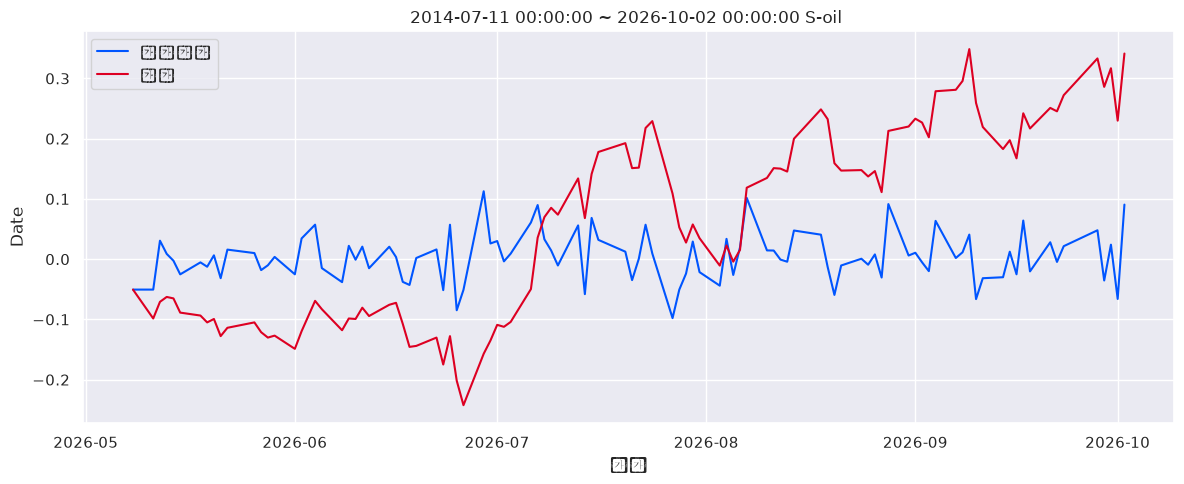

In [26]:
plt.figure(figsize=(12, 5))

# 데이터프레임 지정 없이 x축에 df.index를, y축에 df['컬럼명']을 직접 전달하는 것이 가장 안전합니다.
sns.lineplot(data=df,x=df.index, y=df["pct"], color="#0055ff", label="누적수익")
sns.lineplot(data=df,x=df.index, y=df["cumpro"], color="#dd0022", label="수익")  # clos -> close 수정 확인 필요

plt.title("2014-07-11 00:00:00 ~ 2026-10-02 00:00:00 S-oil ")
plt.xlabel("날짜")  # x축 이름도 추가해주면 더 좋습니다.
plt.ylabel("Date")

plt.legend()
plt.tight_layout()
plt.show()

# **TA-Lib(Technical Analysis Libary)**

* pip install ta-lib
*

In [27]:
import numpy as np 
import pandas as pd 
import talib


# 1. 샘플 데이터 생성 (실제 데이터 적용 시 df['Close'] 등을 사용) 
np.random.seed(42) 
dates = pd.date_range(start="2026-01-01", periods=100) 
close_prices = np.random.normal(loc=100, scale=5, size=100).cumsum() 
df = pd.DataFrame(data={"Close": close_prices}, index=dates) 

# --- 2. TA-Lib 지표 계산 --- # ① 이동평균선 (Moving Average) 
# 단순 이동평균(SMA) 외에도 EMA, WMA 등 형식을 지정할 수 있습니다. 
df["MA_20"] = talib.SMA(df["Close"], timeperiod=20) 

In [32]:
df.head(2)

,Close,MA_20
2026-01-01,102.483571,NaN
2026-01-02,201.792249,NaN


In [29]:

# ② 볼린저 밴드 (Bollinger Bands) # 상단, 중단, 하단 밴드가 순서대로 반환됩니다. 
upperband, middleband, lowerband = talib.BBANDS( 
    df["Close"], 
    timeperiod=20, n
    bdevup=2.0, # 상단 표준편차 승수 
    nbdevdn=2.0, # 하단 표준편차 승수 
    matype=0, # 0: SMA (단순이동평균)
    )
    df["BB_Upper"] = upperband df["BB_Middle"] = middleband df["BB_Lower"] = lowerband 

# ③ 상대강도지수 (Relative Strength Index) 
df["RSI_14"] = talib.RSI(df["Close"], timeperiod=14) 

# 3. 결과 확인 
print(df.tail(10))

SyntaxError: invalid syntax. Perhaps you forgot a comma? (332189301.py, line 4)

# 시각화 

In [31]:
plt.figure(figsize=(10, 3))

sns.lineplot(data=df, x=df.index, y="BB_Lower",  color="#0055ff",  label="하단밴드")
sns.lineplot(data=df, x=df.index, y="ma5",       color="#dd0022",  label="MA5")
sns.lineplot(data=df, x=df.index, y="BB_Upper",  color="#dd0022",  label="상단밴드")

plt.fill_between(df.index, df["BB_Lower"], df["BB_Upper"], color="#0055ff", alpha=0.1, label="밴드 영역")


plt.title("2014-07-11 ~ 2026-10-02 S-Oil(010950) 주가")
plt.ylabel("볼린저밴드")

plt.legend()
plt.tight_layout()
plt.show()